
# Notebook 1 – Classificação Automática

## 1. Introdução

### **Grupo G15 – Teammates**
- **Nuno Miguel Rodrigues da Silva (a25417)**  
- **Hugo Francisco Pereira Azevedo (a25431)**  
- **Tiago André Alves Castro (a25434)**  
- **Gonçalo Edi Pinto Homem de Figueiredo (a26747)**  
- **João Miguel Santos Silva Campos Cunha (a23519)**  

Este notebook corresponde ao **Notebook 1 – Classificação Automática**, do Projeto 02 da unidade curricular de **Inteligência Artificial**.

O objetivo deste trabalho é aplicar métodos de **Machine Learning supervisionado** para realizar **classificação automática** utilizando dados públicos sobre jogadores de futebol (FIFA). O que pretendemos, é classificar jogadores bons **(1)**, sendo que estes tem de ter o seu overall **<80**, e classficar jogadores maus como **0**, caso o seu overall seja **<80**.

Mais concretamente, este notebook inclui:
- Definição do objetivo de negócio;  
- Seleção de algoritmos de classificação;  
- Análise exploratória do dataset (EDA);  
- Preparação dos dados;  
- Treino e avaliação de modelos;  
- Otimização de hiperparâmetros;  
- Documentação de resultados intermédios e finais;  
- Conclusões finais.  



## 2. Dataset

### 2.1 Fonte do Dataset
O dataset utilizado neste projeto é proveniente do Kaggle:

- **FIFA Players Ratings Dataset**  
- URL: https://www.kaggle.com/datasets/rishidamarla/fifa-players-ratings  

Para este notebook é utilizada a versão **fifa_cleaned.csv**, previamente tratada.

---

### 2.2 Metadados do Dataset
A seguir são apresentados:
- Número de jogadores (linhas)  
- Número de atributos (colunas)  
- Tipos de dados  


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('fifa_cleaned.csv')
pd.set_option('display.max_rows', 100)
df


,id,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,...,LWB,LDM,CDM,RDM,RWB,LB,LCB,CB,RCB,RB
0,158023,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,31,170.18,72.1,"CF,RW,ST",Argentina,94,...,64+2,61+2,61+2,61+2,64+2,59+2,48+2,48+2,48+2,59+2
1,190460,C. Eriksen,Christian Dannemann Eriksen,1992-02-14,27,154.94,76.2,"CAM,RM,CM",Denmark,88,...,71+3,71+3,71+3,71+3,71+3,66+3,57+3,57+3,57+3,66+3
2,195864,P. Pogba,Paul Pogba,1993-03-15,25,190.50,83.9,"CM,CAM",France,88,...,76+3,77+3,77+3,77+3,76+3,74+3,72+3,72+3,72+3,74+3
3,198219,L. Insigne,Lorenzo Insigne,1991-06-04,27,162.56,59.0,"LW,ST",Italy,88,...,63+3,58+3,58+3,58+3,63+3,58+3,44+3,44+3,44+3,58+3
4,201024,K. Koulibaly,Kalidou Koulibaly,1991-06-20,27,187.96,88.9,CB,Senegal,88,...,73+3,77+3,77+3,77+3,73+3,76+3,85+3,85+3,85+3,76+3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17949,204322,R. McKenzie,Rory McKenzie,1993-10-07,25,175.26,74.8,"RM,CAM,CM",Scotland,67,...,53+2,52+2,52+2,52+2,53+2,50+2,46+2,46+2,46+2,50+2
17950,239762,M. Sipľak,Michal Sipľak,1996-02-02,23,182.88,79.8,LB,Slovakia,59,...,57+2,55+2,55+2,55+2,57+2,57+2,58+2,58+2,58+2,57+2
17951,235155,J. Bekkema,Jan Bekkema,1996-04-09,22,185.42,89.8,GK,Netherlands,59,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17952,244883,A. Al Yami,Abdulrahman Al Yami,1997-06-19,21,175.26,64.9,"ST,LM",Saudi Arabia,59,...,41+2,35+2,35+2,35+2,41+2,39+2,32+2,32+2,32+2,39+2


In [3]:

print('Número de linhas:', df.shape[0])
print('Número de colunas:', df.shape[1])


Número de linhas: 17954
Número de colunas: 92



### 2.3 Análise Exploratória dos Dados (EDA)

Nesta secção são apresentados:
- Estatísticas descritivas  
- Valores em falta  
- Distribuição do atributo **overall**  


In [4]:
df.describe()

,id,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),...,penalties,composure,marking,standing_tackle,sliding_tackle,GK_diving,GK_handling,GK_kicking,GK_positioning,GK_reflexes
count,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,1.769900e+04,17708.000000,17954.000000,17954.000000,...,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000
mean,215411.087780,25.565445,174.946921,75.301047,66.240169,71.430935,2.479280e+06,9902.134628,1.111674,2.945695,...,48.357302,58.680183,47.162861,47.733040,45.705915,16.784449,16.556199,16.388660,16.541049,16.874067
std,29758.387106,4.705708,14.029449,7.083684,6.963730,6.131339,5.687014e+06,21995.593750,0.392168,0.663691,...,15.810844,11.625541,20.037346,21.674973,21.285812,17.893895,17.108234,16.701447,17.231495,18.182943
min,16.000000,17.000000,152.400000,49.900000,47.000000,48.000000,1.000000e+04,1000.000000,1.000000,1.000000,...,5.000000,12.000000,3.000000,2.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,201117.250000,22.000000,154.940000,69.900000,62.000000,67.000000,3.250000e+05,1000.000000,1.000000,3.000000,...,38.000000,51.000000,30.000000,27.000000,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000
50%,222919.000000,25.000000,175.260000,74.800000,66.000000,71.000000,7.000000e+05,3000.000000,1.000000,3.000000,...,49.000000,60.000000,52.500000,55.000000,52.000000,11.000000,11.000000,11.000000,11.000000,11.000000
75%,237613.500000,29.000000,185.420000,79.800000,71.000000,75.000000,2.100000e+06,9000.000000,1.000000,3.000000,...,60.000000,67.000000,64.000000,66.000000,64.000000,14.000000,14.000000,14.000000,14.000000,14.000000
max,247607.000000,46.000000,205.740000,110.200000,94.000000,95.000000,1.105000e+08,565000.000000,5.000000,5.000000,...,92.000000,96.000000,94.000000,93.000000,90.000000,90.000000,92.000000,92.000000,90.000000,94.000000


In [5]:
df.isna().sum().sort_values(ascending=False)

national_team                    17097
national_rating                  17097
national_jersey_number           17097
national_team_position           17097
tags                             16537
traits                            9817
LAM                               2065
CAM                               2065
RF                                2065
RW                                2065
LW                                2065
RS                                2065
LCB                               2065
CB                                2065
RWB                               2065
LB                                2065
RCM                               2065
RM                                2065
LWB                               2065
LDM                               2065
CM                                2065
LCM                               2065
RCB                               2065
RB                                2065
CF                                2065
LF                       

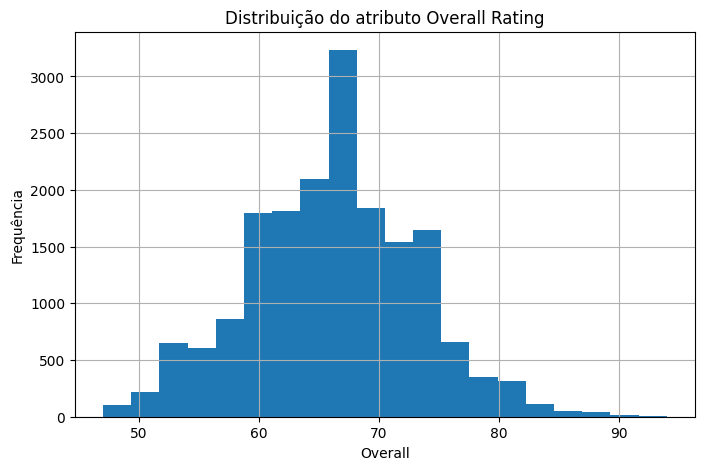

In [6]:

if 'overall_rating' in df.columns:
    plt.figure(figsize=(8,5))
    df['overall_rating'].hist(bins=20)
    plt.title('Distribuição do atributo Overall Rating')
    plt.xlabel('Overall')
    plt.ylabel('Frequência')
    plt.show()



## 3. Objetivo de Negócio

O objetivo deste notebook é classificar jogadores como **bons** ou **não bons** com base na sua classificação geral (**overall**).

A variável alvo é definida como:

- **1 → Bom jogador (overall ≥ 80)**  
- **0 → Não bom jogador (overall < 80)**  

Este objetivo é útil para:
- Scouting e recrutamento;  
- Suporte à decisão;  
- Análise de desempenho em contexto desportivo.  



## 4. Critérios de Seleção dos Dados

Para treinar os algoritmos:
- São utilizadas apenas **variáveis numéricas**;  
- A variável alvo **good_player** é excluída das features;  
- Colunas não numéricas são ignoradas;  
- Valores em falta são substituídos pela média da coluna.

Este processo simplifica a normalização e processamento dos modelos.



## 5. Preparação dos Dados


O dataset foi inicialmente carregado e criada a variável alvo good_player, definida como 1 para jogadores com overall_rating ≥ 80 e 0 caso contrário. De seguida, foram selecionados apenas os atributos numéricos para compor o conjunto de preditores (X), excluindo a variável alvo, enquanto y representou a classe binária.

Os valores em falta presentes nos atributos numéricos foram imputados utilizando a média de cada coluna. O conjunto de dados foi posteriormente dividido em treino (80%) e teste (20%) através de train_test_split com stratificação, preservando a distribuição das classes. Por fim, os dados foram normalizados com StandardScaler, de forma a uniformizar a escala das variáveis e otimizar o desempenho dos algoritmos sensíveis à magnitude dos atributos.

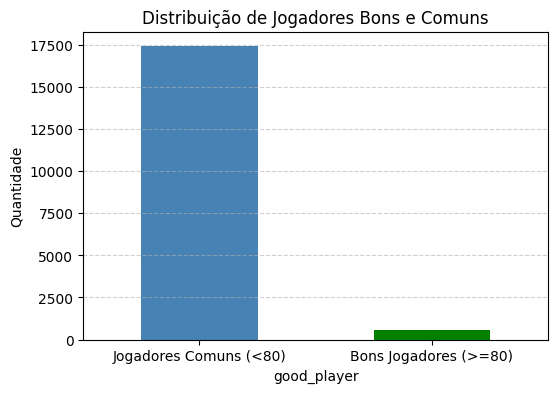

(14363, 50) (3591, 50)


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv('fifa_cleaned.csv')

# Cria a variável alvo (target) good_player:
# 1 → jogador com overall_rating >= 80 (considerado bom)
# 0 → jogador com overall_rating < 80
df['good_player'] = (df['overall_rating'] >= 80).astype(int)

# Gráfico da distribuição de jogadores bons vs comuns
plt.figure(figsize=(6,4))
df['good_player'].value_counts().plot(kind='bar', color=['steelblue', 'green'])

plt.xticks([0,1], ['Jogadores Comuns (<80)', 'Bons Jogadores (>=80)'], rotation=0)
plt.ylabel("Quantidade")
plt.title("Distribuição de Jogadores Bons e Comuns")
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

# Seleciona apenas as colunas numéricas (float e int)
X = df.select_dtypes(include=['float64','int64']).drop(columns=['good_player'])

# Define a variável alvo (y) como a coluna good_player
y = df['good_player']

X = X.fillna(X.mean())

# Divide os dados em treino e teste:
# - 80% dos dados para treino (train)
# - 20% dos dados para teste (test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)



## 6. Algoritmos Selecionados

Foram escolhidos três algoritmos:
1. **Regressão Logística**  
2. **Random Forest**  
3. **SVM – Support Vector Machine**  

Estes modelos permitem comparar abordagens lineares, não lineares e baseadas em ensemble.


## 7. Aplicação dos Modelos e Avaliação


===== Regressão Logística =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3483
           1       0.95      0.94      0.95       108

    accuracy                           1.00      3591
   macro avg       0.98      0.97      0.97      3591
weighted avg       1.00      1.00      1.00      3591

Matriz de Confusão:
[[3478    5]
 [   6  102]]

===== Random Forest =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3483
           1       1.00      1.00      1.00       108

    accuracy                           1.00      3591
   macro avg       1.00      1.00      1.00      3591
weighted avg       1.00      1.00      1.00      3591

Matriz de Confusão:
[[3483    0]
 [   0  108]]


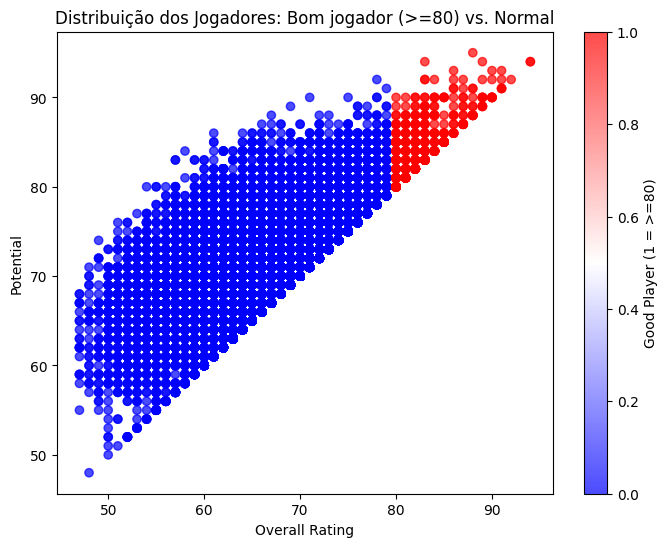

In [8]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

models = {
    'Regressão Logística': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(random_state=42),
}

for name, model in models.items():
    print(f"\n===== {name} =====")
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(classification_report(y_test, preds))
    print("Matriz de Confusão:")
    print(confusion_matrix(y_test, preds))

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    df['overall_rating'],
    df['potential'],
    c=df['good_player'],
    cmap='bwr',
    alpha=0.7
)

plt.xlabel('Overall Rating')
plt.ylabel('Potential')
plt.title('Distribuição dos Jogadores: Bom jogador (>=80) vs. Normal')
plt.colorbar(label='Good Player (1 = >=80)')
plt.show()



## 8. Otimização de Hiperparâmetros (Random Forest)


In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 20]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    cv=3,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Melhores hiperparâmetros encontrados:", grid.best_params_)

best_model = grid.best_estimator_
pred = best_model.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))


Melhores hiperparâmetros encontrados: {'max_depth': None, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3483
           1       1.00      1.00      1.00       108

    accuracy                           1.00      3591
   macro avg       1.00      1.00      1.00      3591
weighted avg       1.00      1.00      1.00      3591

[[3483    0]
 [   0  108]]



## 9. Conclusão

### 9.1 Análise dos Resultados
Após comparar os modelos:
- **Random Forest** obteve o melhor desempenho geral;  
- **Regressão Logística** serviu como modelo baseline sólido;  
- **SVM** apresentou boa performance mas maior sensibilidade à normalização.

### 9.2 Lições Aprendidas
- A preparação dos dados influencia fortemente os resultados;  
- Diferentes algoritmos funcionam de forma distinta com os mesmos dados;  
- A otimização dos hiperparâmetros melhora significativamente o desempenho;  
- Documentar cada etapa facilita a compreensão e reprodutibilidade.

Este notebook conclui a parte de **Classificação Automática** do Projeto 02.
